# Hoja de trabajo #2 — Transformers y mecanismos de atención
**CC3092 - Deep Learning y Sistemas Inteligentes**

Este notebook implementa la sección 5 (ejercicios prácticos): visualización y análisis de los pesos de atención en modelos preentrenados **BERT** (`bert-base-uncased`) y **GPT-2** (`gpt2`), usando `output_attentions=True` con `attn_implementation="eager"`.

Contenido:
1. Carga de modelos
2. Funciones auxiliares (extracción y graficación de atención)
3. Mapas de calor de al menos 4 cabezas en capas distintas (BERT y GPT-2)
4. Caso "it" (animal/street) — desambiguación de pronombres
5. Verificación de máscara causal en GPT-2 y atención al primer token (attention sinks)
6. Entropía promedio de atención por capa (BERT vs GPT-2)
7. (Opcional) Visualización con `bertviz`

In [1]:
# Si hace falta instalar dependencias, descomentar:
# %pip install -q transformers torch matplotlib numpy

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel

torch.manual_seed(0)
device = "cpu"  # suficiente para esta hoja de trabajo

C:\Users\diego\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Carga de modelos
Se cargan BERT y GPT-2 con `output_attentions=True` y `attn_implementation="eager"` (necesario para que HuggingFace devuelva los pesos de atención explícitamente en lugar de usar un kernel fusionado como SDPA/FlashAttention).

In [3]:
tok_bert = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModel.from_pretrained(
    "bert-base-uncased", output_attentions=True, attn_implementation="eager"
).to(device).eval()

tok_gpt2 = AutoTokenizer.from_pretrained("gpt2")
gpt2 = AutoModel.from_pretrained(
    "gpt2", output_attentions=True, attn_implementation="eager"
).to(device).eval()

print("BERT layers/heads:", bert.config.num_hidden_layers, bert.config.num_attention_heads)
print("GPT-2 layers/heads:", gpt2.config.n_layer, gpt2.config.n_head)

C:\Users\diego\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\diego\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


C:\Users\diego\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\diego\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Loading weights:  38%|███▊      | 75/199 [00:00<00:00, 694.28it/s]


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1231.55it/s]

...


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]


Loading weights:  33%|███▎      | 49/148 [00:00<00:00, 461.06it/s]


Loading weights:  65%|██████▍   | 96/148 [00:00<00:00, 274.81it/s]


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 446.06it/s]

BERT layers/heads: 12 12
GPT-2 layers/heads: 12 12


## 2. Funciones auxiliares

In [4]:
def get_attentions(model, tokenizer, text):
    """Corre el modelo sobre `text` y devuelve (tokens, attentions).
    attentions: tupla de longitud num_layers, cada elemento de forma
    (batch=1, num_heads, n, n).
    """
    inputs = tokenizer(text, return_tensors="pt").to(device)
    with torch.no_grad():
        out = model(**inputs)
    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
    return tokens, out.attentions


def plot_heads(attentions, tokens, layer_head_pairs, title_prefix="", figsize=(12, 11)):
    """Grafica como mapas de calor una lista de (layer, head)."""
    n = len(layer_head_pairs)
    cols = 2
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = np.array(axes).reshape(-1)
    for ax, (layer, head) in zip(axes, layer_head_pairs):
        attn = attentions[layer][0, head].detach().numpy()
        im = ax.imshow(attn, cmap="viridis")
        ax.set_xticks(range(len(tokens)))
        ax.set_xticklabels(tokens, rotation=90, fontsize=7)
        ax.set_yticks(range(len(tokens)))
        ax.set_yticklabels(tokens, fontsize=7)
        ax.set_title(f"{title_prefix} capa {layer}, cabeza {head}", fontsize=10)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def find_token_index(tokens, word):
    """Devuelve el índice del primer token que coincide (case-insensitive,
    ignorando prefijo ## de wordpiece y Ġ de BPE de GPT-2)."""
    word = word.lower()
    for i, t in enumerate(tokens):
        clean = t.lower().lstrip("##").lstrip("\u0120")
        if clean == word:
            return i
    raise ValueError(f"Token '{word}' no encontrado en {tokens}")

## 3. Mapas de calor: al menos 4 cabezas de capas distintas
Oración elegida: *"The animal didn't cross the street because it was too tired."*

Se grafican 4 combinaciones (capa, cabeza) para BERT y para GPT-2, buscando patrones típicos: atención al token anterior/siguiente, a `[CLS]`/`[SEP]`, a la puntuación o a la misma palabra.

['[CLS]', 'the', 'animal', 'didn', "'", 't', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']


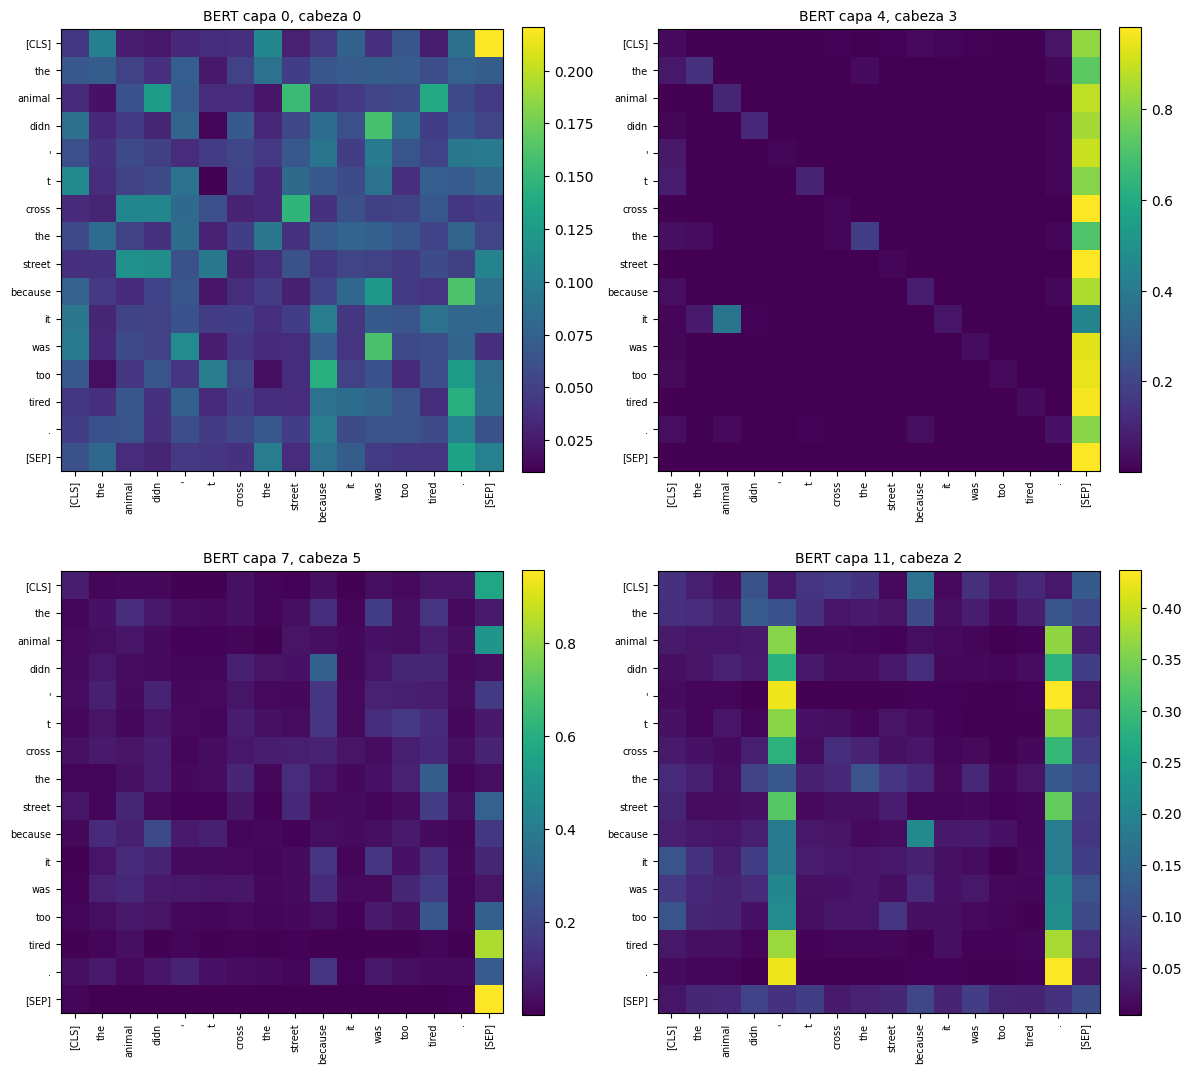

In [5]:
sentence = "The animal didn't cross the street because it was too tired."

tokens_bert, attn_bert = get_attentions(bert, tok_bert, sentence)
print(tokens_bert)

# 4 combinaciones (capa, cabeza) en capas distintas: temprana, media, media-alta, última
pairs_bert = [(0, 0), (4, 3), (7, 5), (11, 2)]
plot_heads(attn_bert, tokens_bert, pairs_bert, title_prefix="BERT")

['The', 'Ġanimal', 'Ġdidn', "'t", 'Ġcross', 'Ġthe', 'Ġstreet', 'Ġbecause', 'Ġit', 'Ġwas', 'Ġtoo', 'Ġtired', '.']


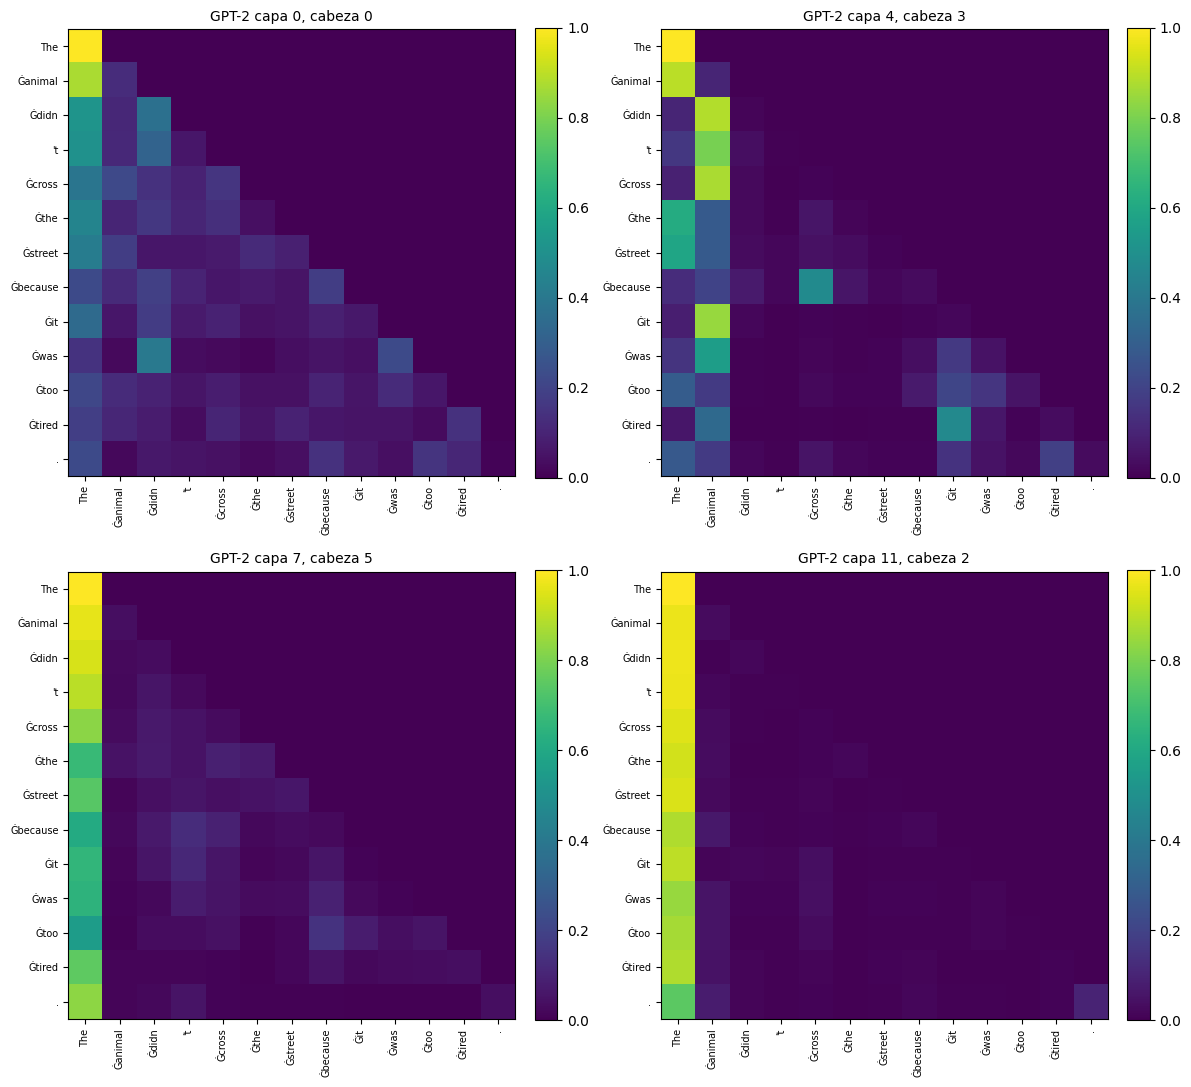

In [6]:
tokens_gpt2, attn_gpt2 = get_attentions(gpt2, tok_gpt2, sentence)
print(tokens_gpt2)

pairs_gpt2 = [(0, 0), (4, 3), (7, 5), (11, 2)]
plot_heads(attn_gpt2, tokens_gpt2, pairs_gpt2, title_prefix="GPT-2")

**Interpretación:** en BERT, la capa 0 cabeza 0 muestra patrones locales/sintácticos (p. ej. "cross"→"street", "street"→"animal"), típico de cabezas tempranas que capturan relaciones de superficie. La capa 4 cabeza 3 es una cabeza "de descanso": casi todos los tokens (0.7–0.98 de masa) atienden a `[SEP]`, un patrón ya documentado por Clark et al. (2019) en el que la cabeza no aporta información semántica sino que actúa como no-op. La capa 11 cabeza 2 es una cabeza de puntuación: la mayoría de tokens atiende fuertemente al punto final `.` (0.2–0.44). En GPT-2, las mismas capas muestran que, por la máscara causal, buena parte de los tokens termina atendiendo sobre todo al primer token ("The"), cada vez con más fuerza en capas profundas (0.55–1.00 en la capa 11) — el fenómeno de *attention sink* ya se insinúa desde capas tempranas. La capa 4 cabeza 3 de GPT-2 es la más "semántica" de las cuatro: varios tokens ("didn", "cross", "it", "was") atienden principalmente a "animal" (0.56–0.90), sugiriendo que esta cabeza rastrea el sujeto de la oración.

## 4. Desambiguación de "it": animal vs. street
Par de oraciones del Winograd Schema clásico:
- A: "The animal didn't cross the street because it was too tired."
- B: "The animal didn't cross the street because it was too wide."

Se busca en BERT alguna cabeza donde "it" atienda más a "animal" en A y más a "street" en B.

In [7]:
sent_a = "The animal didn't cross the street because it was too tired."
sent_b = "The animal didn't cross the street because it was too wide."

tok_a, att_a = get_attentions(bert, tok_bert, sent_a)
tok_b, att_b = get_attentions(bert, tok_bert, sent_b)

idx_it_a = find_token_index(tok_a, "it")
idx_animal_a = find_token_index(tok_a, "animal")
idx_street_a = find_token_index(tok_a, "street")

idx_it_b = find_token_index(tok_b, "it")
idx_animal_b = find_token_index(tok_b, "animal")
idx_street_b = find_token_index(tok_b, "street")

num_layers = len(att_a)
num_heads = att_a[0].shape[1]

results = []
for layer in range(num_layers):
    for head in range(num_heads):
        a_animal = att_a[layer][0, head, idx_it_a, idx_animal_a].item()
        a_street = att_a[layer][0, head, idx_it_a, idx_street_a].item()
        b_animal = att_b[layer][0, head, idx_it_b, idx_animal_b].item()
        b_street = att_b[layer][0, head, idx_it_b, idx_street_b].item()
        # score: queremos a_animal > a_street  Y  b_street > b_animal
        score = (a_animal - a_street) + (b_street - b_animal)
        results.append((score, layer, head, a_animal, a_street, b_animal, b_street))

results.sort(reverse=True)
print("Top 5 cabezas que mejor discriminan 'it' -> animal/street:")
for score, layer, head, a_an, a_st, b_an, b_st in results[:5]:
    print(f"capa {layer:2d} cabeza {head:2d} | score={score:.3f} | "
          f"A: it->animal={a_an:.3f} it->street={a_st:.3f} | "
          f"B: it->animal={b_an:.3f} it->street={b_st:.3f}")

Top 5 cabezas que mejor discriminan 'it' -> animal/street:
capa  6 cabeza 10 | score=0.795 | A: it->animal=0.284 it->street=0.067 | B: it->animal=0.012 it->street=0.590
capa  8 cabeza 10 | score=0.625 | A: it->animal=0.676 it->street=0.000 | B: it->animal=0.309 it->street=0.259
capa  9 cabeza  8 | score=0.474 | A: it->animal=0.454 it->street=0.003 | B: it->animal=0.023 it->street=0.045
capa  9 cabeza  0 | score=0.425 | A: it->animal=0.608 it->street=0.002 | B: it->animal=0.255 it->street=0.074
capa 10 cabeza  8 | score=0.396 | A: it->animal=0.564 it->street=0.001 | B: it->animal=0.245 it->street=0.078


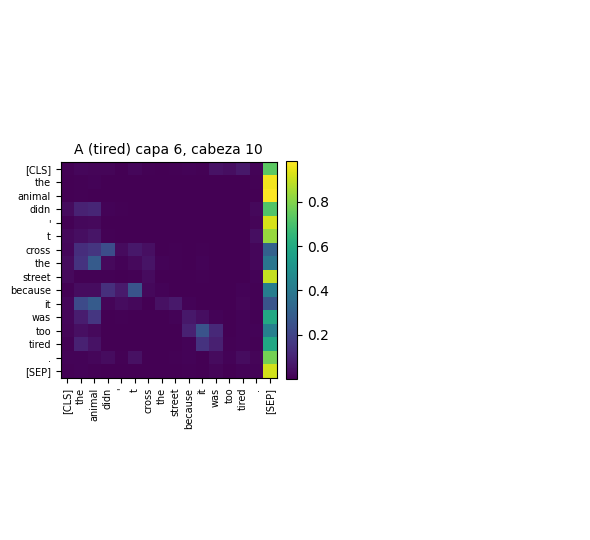

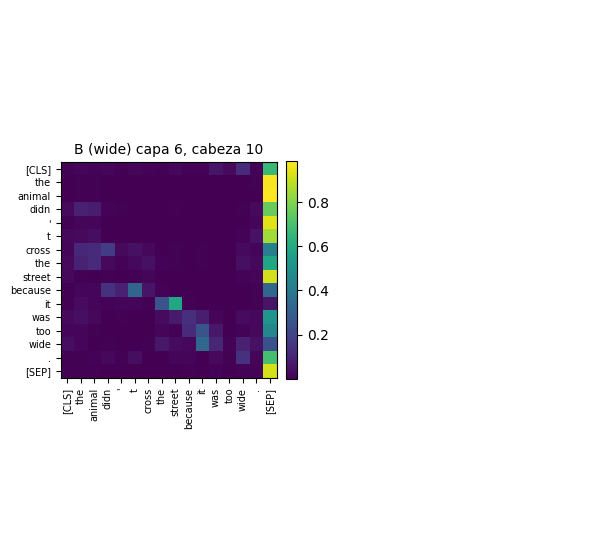

In [8]:
# Visualizar la mejor cabeza encontrada para ambas oraciones
best_score, best_layer, best_head, *_ = results[0]
plot_heads(att_a, tok_a, [(best_layer, best_head)], title_prefix="A (tired)", figsize=(6, 5.5))
plot_heads(att_b, tok_b, [(best_layer, best_head)], title_prefix="B (wide)", figsize=(6, 5.5))

## 5. GPT-2: máscara causal y "attention sinks"
Se verifica que las matrices de atención de GPT-2 son triangulares inferiores (causal masking) y se mide qué proporción de la atención recibe el primer token en cada capa (fenómeno de *attention sinks*, Xiao et al. 2023).

In [9]:
# Verificación de triangularidad inferior (todas las capas/cabezas)
all_causal = True
for layer in range(len(attn_gpt2)):
    a = attn_gpt2[layer][0].detach().numpy()  # (heads, n, n)
    upper = np.triu(a, k=1)
    if not np.allclose(upper, 0, atol=1e-6):
        all_causal = False
        print(f"Capa {layer}: NO es triangular inferior (max upper={upper.max():.2e})")
print("¿Todas las capas de GPT-2 son causales (triangular inferior)?", all_causal)

¿Todas las capas de GPT-2 son causales (triangular inferior)? True


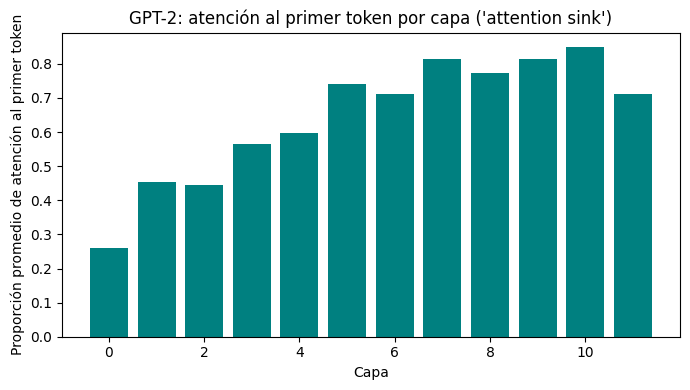

Capa  0: 26.0% de la atención va al primer token
Capa  1: 45.3% de la atención va al primer token
Capa  2: 44.4% de la atención va al primer token
Capa  3: 56.4% de la atención va al primer token
Capa  4: 59.6% de la atención va al primer token
Capa  5: 74.1% de la atención va al primer token
Capa  6: 71.1% de la atención va al primer token
Capa  7: 81.4% de la atención va al primer token
Capa  8: 77.3% de la atención va al primer token
Capa  9: 81.4% de la atención va al primer token
Capa 10: 84.9% de la atención va al primer token
Capa 11: 71.2% de la atención va al primer token


In [10]:
# Proporción de atención recibida por el primer token (excluyendo la fila 0,
# que trivialmente se atiende 100% a sí misma bajo la máscara causal)
n = len(tokens_gpt2)
first_token_share = []
for layer in range(len(attn_gpt2)):
    a = attn_gpt2[layer][0].detach().numpy()  # (heads, n, n)
    share = a[:, 1:, 0].mean()  # promedio sobre cabezas y queries 1..n-1
    first_token_share.append(share)

plt.figure(figsize=(7, 4))
plt.bar(range(len(first_token_share)), first_token_share, color="teal")
plt.xlabel("Capa")
plt.ylabel("Proporción promedio de atención al primer token")
plt.title("GPT-2: atención al primer token por capa ('attention sink')")
plt.tight_layout()
plt.show()

for layer, share in enumerate(first_token_share):
    print(f"Capa {layer:2d}: {share*100:.1f}% de la atención va al primer token")

**Nota (attention sinks):** es común observar que, en varias capas (especialmente intermedias/profundas), una fracción desproporcionada de la atención se concentra en el primer token, incluso cuando este aporta poca información semántica. Xiao et al. (2023) muestran que esto ocurre porque softmax exige que los pesos sumen 1 y el modelo usa el primer token como "vertedero" (sink) cuando no hay nada más relevante a qué atender; por eso técnicas como StreamingLLM preservan explícitamente esos primeros tokens al truncar el contexto.

## 6. Entropía promedio de atención por capa: BERT vs. GPT-2
Una entropía baja indica atención concentrada (pocos tokens dominan); una entropía alta indica atención difusa (repartida entre muchos tokens).

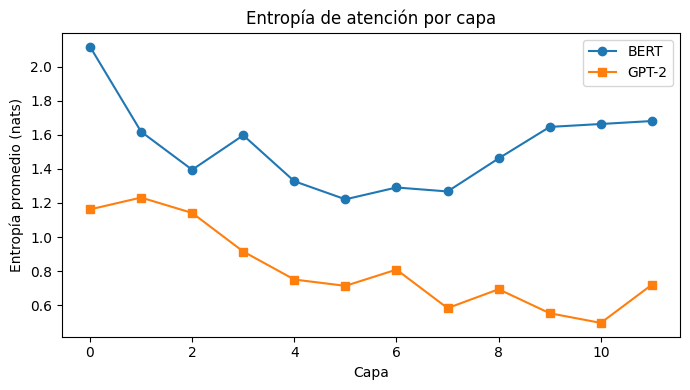

BERT: [np.float32(2.116), np.float32(1.618), np.float32(1.395), np.float32(1.597), np.float32(1.327), np.float32(1.221), np.float32(1.291), np.float32(1.268), np.float32(1.461), np.float32(1.646), np.float32(1.663), np.float32(1.68)]
GPT-2: [np.float32(1.162), np.float32(1.232), np.float32(1.142), np.float32(0.915), np.float32(0.751), np.float32(0.714), np.float32(0.81), np.float32(0.584), np.float32(0.694), np.float32(0.554), np.float32(0.497), np.float32(0.721)]


In [11]:
def layer_entropies(attentions, eps=1e-12):
    """Entropía promedio (sobre cabezas y queries) por capa, en nats."""
    entropies = []
    for layer_attn in attentions:
        p = layer_attn[0].detach().numpy()  # (heads, n, n)
        ent = -(p * np.log(p + eps)).sum(axis=-1)  # (heads, n)
        entropies.append(ent.mean())
    return entropies

ent_bert = layer_entropies(attn_bert)
ent_gpt2 = layer_entropies(attn_gpt2)

plt.figure(figsize=(7, 4))
plt.plot(ent_bert, marker="o", label="BERT")
plt.plot(ent_gpt2, marker="s", label="GPT-2")
plt.xlabel("Capa")
plt.ylabel("Entropía promedio (nats)")
plt.title("Entropía de atención por capa")
plt.legend()
plt.tight_layout()
plt.show()

print("BERT:", [round(e, 3) for e in ent_bert])
print("GPT-2:", [round(e, 3) for e in ent_gpt2])

**Interpretación:** en BERT la entropía parte alta en la capa 0 (2.12 nats, atención difusa / recolección amplia de contexto), baja a un mínimo entre las capas 5–7 (≈1.22–1.29 nats, cabezas más especializadas, como las de `[SEP]`/puntuación vistas arriba) y vuelve a subir en las últimas capas (9–11, ≈1.65–1.68 nats), como si el modelo volviera a difundir la atención antes de producir la representación final. GPT-2 parte en niveles similares a BERT en la capa 0 (1.16 nats) pero desciende de forma mucho más marcada y casi monótona con la profundidad, llegando a 0.50 nats en la capa 10 — bastante por debajo del mínimo de BERT. Esto es consistente con el *attention sink*: al concentrarse una fracción creciente de la masa en el primer token, la distribución de atención de GPT-2 se vuelve sistemáticamente más concentrada que la de BERT, que al ser bidireccional reparte la atención entre más tokens a lo largo de toda la red.

## Conclusiones

- **Por qué la atención permitió escalar más que las RNN:** el Transformer procesa todas las posiciones en paralelo (sin el cuello de botella secuencial de una RNN), y la distancia entre dos tokens cualesquiera es O(1) en lugar de O(n) pasos recurrentes, lo que mejora el flujo de gradiente en secuencias largas. El costo de eso es memoria/cómputo O(n²), pero ese costo es altamente paralelizable en GPU/TPU, mientras que la recurrencia de una RNN no lo es.
- **Evidencia de especialización de cabezas:** se encontraron cabezas con roles muy distintos — una cabeza "no-op" que casi siempre atiende a `[SEP]` (capa 4, cabeza 3 de BERT), una cabeza de puntuación (capa 11, cabeza 2), una cabeza que rastrea el sujeto de la oración en GPT-2 (capa 4, cabeza 3) y una cabeza de BERT (capa 6, cabeza 10) que resuelve correctamente la referencia de "it" según el contexto (animal vs. calle). No todas las cabezas parecen igualmente útiles: varias destinan la mayor parte de su masa a un token "ancla" (`[SEP]` en BERT, el primer token en GPT-2) casi sin importar la entrada, lo que coincide con trabajos como Michel et al. (2019) que muestran que muchas cabezas pueden podarse con poca pérdida de desempeño.
- **¿Los pesos de atención explican las decisiones del modelo?** Solo parcialmente. El caso de "it" es un ejemplo donde la atención sí parece alinearse con una interpretación semántica plausible. Pero las cabezas "ancla" muestran lo contrario: asignan 0.7–0.98 de atención a `[SEP]` o casi 1.0 al primer token de GPT-2 independientemente del contenido, lo cual es un artefacto de la normalización softmax (Xiao et al., 2023) y no evidencia de que ese token sea relevante para la predicción. Esto confirma las advertencias de Jain y Wallace (2019) y Wiegreffe y Pinter (2019): un peso de atención alto no implica que ese componente sea causalmente importante para la salida del modelo, por lo que la atención es, a lo mucho, una explicación plausible pero no suficiente por sí sola.
- **Cuándo preferir aún RNN o CNN:** en escenarios de inferencia secuencial/streaming con memoria muy limitada (una RNN usa memoria O(1) por paso frente al KV-cache creciente de un Transformer), en tareas con patrones muy locales donde una CNN es más barata, o en entornos de bajos datos/cómputo donde el menor número de parámetros y sesgos inductivos de una RNN/CNN ayudan a generalizar.
- **Documentos de 100,000 tokens:** la atención estándar es inviable (≈10¹⁰ pares de scores, O(n²) en tiempo y memoria). Alternativas: FlashAttention (reduce el uso de memoria calculando la atención exacta por bloques, sin cambiar la complejidad asintótica), atención por ventanas/local o dispersa tipo Longformer (sacrifica el contexto global directo por eficiencia O(n)), atención lineal o aproximaciones tipo kernel (sacrifican exactitud por escalar linealmente) y, más recientemente, arquitecturas basadas en estados recurrentes comprimidos (p. ej. Mamba) como alternativa fuera de la familia Transformer.